# 07 · Attention and the Transformer Encoder

Recurrence passes information step by step. **Self-attention** lets every token look at every other token in one step.

**Scaled dot-product attention.** Each token makes a query $q$, key $k$ and value $v$ (linear maps of its embedding). A token's output is a weighted average of all values, weighted by how well its query matches each key:
$$A=\operatorname{softmax}\!\Big(\frac{QK^{\top}}{\sqrt{d_k}}\Big),\qquad \text{out}=AV$$
The $\sqrt{d_k}$ keeps dot products from growing with dimension and saturating the softmax.

**Multi-head**: run $h$ attentions in parallel on slices of the feature space (each can learn a different relation), then concatenate and mix with $W_o$.

**Positional encoding.** Attention is permutation-equivariant — it doesn't know order. Add sinusoidal position vectors to the embeddings so token *position* is available:
$$PE_{(pos,2i)}=\sin\!\big(pos/10000^{2i/d}\big),\quad PE_{(pos,2i+1)}=\cos\!\big(pos/10000^{2i/d}\big)$$

**Encoder block (pre-LN):** $h = x + \text{MHA}(\text{LN}(x))$, then $\text{out} = h + \text{FFN}(\text{LN}(h))$. Residuals give gradients a direct path; LayerNorm stabilizes activations.

**Softmax backward** (the trickiest piece): with $A=\operatorname{softmax}(S)$ per row, $dS = A\odot\big(dA - \sum_j dA_{j}A_{j}\big)$.

## The experiment
Label = **does the first token reappear later?** This needs *content lookup* (attention) and knowing *which token is first* (positional encoding). Mean-pooling afterwards means that without position info the model literally can't tell which token was first — a clean ablation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## Building blocks
Each layer stores its gradients in preallocated arrays (filled in place on `backward`), so a single optimizer can hold `(param, grad)` pairs for the whole model.

In [2]:
class Linear:
    def __init__(self, d_in, d_out):
        self.W = np.random.randn(d_in, d_out) / np.sqrt(d_in)
        self.b = np.zeros(d_out)
        self.dW, self.db = np.zeros_like(self.W), np.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        x2, d2 = self.x.reshape(-1, self.W.shape[0]), dout.reshape(-1, self.W.shape[1])
        self.dW[...] = x2.T @ d2
        self.db[...] = d2.sum(axis=0)
        return (d2 @ self.W.T).reshape(self.x.shape)

    def parameters(self):
        return [(self.W, self.dW), (self.b, self.db)]

In [3]:
class Embedding:
    def __init__(self, vocab, d):
        self.W = np.random.randn(vocab, d)
        self.dW = np.zeros_like(self.W)

    def forward(self, tokens):
        self.tokens = tokens
        return self.W[tokens]

    def backward(self, dout):
        self.dW[...] = 0
        np.add.at(self.dW, self.tokens, dout)

    def parameters(self):
        return [(self.W, self.dW)]

In [4]:
class LayerNorm:
    """Normalize each token's feature vector (last axis) to zero mean / unit variance."""

    def __init__(self, d, eps=1e-5):
        self.g, self.b, self.eps = np.ones(d), np.zeros(d), eps
        self.dg, self.db = np.zeros(d), np.zeros(d)

    def forward(self, x):
        mu = x.mean(axis=-1, keepdims=True)
        var = x.var(axis=-1, keepdims=True)
        self.std_inv = 1.0 / np.sqrt(var + self.eps)
        self.xhat = (x - mu) * self.std_inv
        return self.g * self.xhat + self.b

    def backward(self, dout):
        axes = tuple(range(dout.ndim - 1))
        self.dg[...] = (dout * self.xhat).sum(axis=axes)
        self.db[...] = dout.sum(axis=axes)
        dxhat = dout * self.g
        D = dout.shape[-1]
        return self.std_inv / D * (
            D * dxhat
            - dxhat.sum(axis=-1, keepdims=True)
            - self.xhat * (dxhat * self.xhat).sum(axis=-1, keepdims=True)
        )

    def parameters(self):
        return [(self.g, self.dg), (self.b, self.db)]

In [5]:
def positional_encoding(L, d):
    pos = np.arange(L)[:, None]
    i = np.arange(0, d, 2)[None, :]
    angle = pos / np.power(10000.0, i / d)
    pe = np.zeros((L, d))
    pe[:, 0::2] = np.sin(angle)
    pe[:, 1::2] = np.cos(angle)
    return pe

## Multi-head self-attention
`A` has shape `(batch, heads, L, L)`: row *i* = how much token *i* attends to every token. We keep it for visualization.

In [6]:
class MultiHeadAttention:
    def __init__(self, d, heads):
        assert d % heads == 0
        self.h, self.dk = heads, d // heads
        self.q, self.k, self.v, self.o = Linear(d, d), Linear(d, d), Linear(d, d), Linear(d, d)

    def split(self, x):  # (N,L,d) -> (N,h,L,dk)
        N, L, _ = x.shape
        return x.reshape(N, L, self.h, self.dk).transpose(0, 2, 1, 3)

    def merge(self, x):  # (N,h,L,dk) -> (N,L,d)
        N, _, L, _ = x.shape
        return x.transpose(0, 2, 1, 3).reshape(N, L, self.h * self.dk)

    def forward(self, x):
        self.Q, self.K, self.V = self.split(self.q.forward(x)), self.split(self.k.forward(x)), self.split(self.v.forward(x))
        scores = self.Q @ self.K.swapaxes(-1, -2) / np.sqrt(self.dk)
        scores -= scores.max(axis=-1, keepdims=True)  # numerical stability
        e = np.exp(scores)
        self.A = e / e.sum(axis=-1, keepdims=True)  # (N,h,L,L): row i = how much token i attends to each token
        return self.o.forward(self.merge(self.A @ self.V))

    def backward(self, dout):
        dctx = self.split(self.o.backward(dout))
        dA = dctx @ self.V.swapaxes(-1, -2)
        dV = self.A.swapaxes(-1, -2) @ dctx
        dscores = self.A * (dA - (dA * self.A).sum(axis=-1, keepdims=True)) / np.sqrt(self.dk)  # softmax backward
        dQ = dscores @ self.K
        dK = dscores.swapaxes(-1, -2) @ self.Q
        return self.q.backward(self.merge(dQ)) + self.k.backward(self.merge(dK)) + self.v.backward(self.merge(dV))

    def parameters(self):
        return sum((m.parameters() for m in (self.q, self.k, self.v, self.o)), [])

## Encoder block, model, optimizer

In [7]:
class EncoderBlock:
    """Pre-LN transformer encoder block: x + MHA(LN(x)), then h + FFN(LN(h))."""

    def __init__(self, d, heads, d_ff):
        self.ln1, self.mha = LayerNorm(d), MultiHeadAttention(d, heads)
        self.ln2, self.ff1, self.ff2 = LayerNorm(d), Linear(d, d_ff), Linear(d_ff, d)

    def forward(self, x):
        h = x + self.mha.forward(self.ln1.forward(x))
        a = self.ff1.forward(self.ln2.forward(h))
        self.relu_mask = a > 0
        return h + self.ff2.forward(a * self.relu_mask)

    def backward(self, dout):
        dff = self.ff2.backward(dout) * self.relu_mask
        dh = dout + self.ln2.backward(self.ff1.backward(dff))
        return dh + self.ln1.backward(self.mha.backward(dh))

    def parameters(self):
        return sum((m.parameters() for m in (self.ln1, self.mha, self.ln2, self.ff1, self.ff2)), [])

In [8]:
class TransformerClassifier:
    def __init__(self, vocab, max_len, d=32, heads=4, d_ff=64, n_blocks=2, use_pos=True):
        self.emb = Embedding(vocab, d)
        self.pe = positional_encoding(max_len, d) if use_pos else 0.0
        self.blocks = [EncoderBlock(d, heads, d_ff) for _ in range(n_blocks)]
        self.ln_f = LayerNorm(d)
        self.head = Linear(d, 1)

    def forward(self, tokens):
        x = self.emb.forward(tokens) + self.pe
        for blk in self.blocks:
            x = blk.forward(x)
        self.L = x.shape[1]
        pooled = self.ln_f.forward(x).mean(axis=1)
        self.p = 1 / (1 + np.exp(-self.head.forward(pooled)))
        return self.p

    def loss(self, y):
        p = np.clip(self.p, 1e-12, 1 - 1e-12)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def backward(self, y):
        dlogit = (self.p - y) / len(y)  # sigmoid + BCE combined
        dpooled = self.head.backward(dlogit)
        dx = self.ln_f.backward(np.repeat(dpooled[:, None, :] / self.L, self.L, axis=1))
        for blk in reversed(self.blocks):
            dx = blk.backward(dx)
        self.emb.backward(dx)

    def parameters(self):
        layers = [self.emb, *self.blocks, self.ln_f, self.head]
        return sum((m.parameters() for m in layers), [])

In [9]:
class Adam:
    def __init__(self, pairs, lr=3e-3, b1=0.9, b2=0.999, eps=1e-8):
        self.pairs, self.lr, self.b1, self.b2, self.eps, self.t = pairs, lr, b1, b2, eps, 0
        self.m = [np.zeros_like(p) for p, _ in pairs]
        self.v = [np.zeros_like(p) for p, _ in pairs]

    def step(self):
        self.t += 1
        for i, (p, g) in enumerate(self.pairs):
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * g ** 2
            m_hat = self.m[i] / (1 - self.b1 ** self.t)
            v_hat = self.v[i] / (1 - self.b2 ** self.t)
            p -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

## Verify backward against finite differences
Attention backward is easy to get subtly wrong. This check perturbs random entries of **every** parameter array and compares to the analytic gradient.

Note: the attention **key bias** has a true gradient of exactly 0 (softmax ignores a constant shift added to all keys), so the relative-error denominator has a small floor to avoid reporting float noise.

In [10]:
def grad_check(loss_fn, pairs, samples_per_param=3, eps=1e-5, seed=0):
    """Compare analytic grads to central finite differences; return worst error.

    loss_fn: () -> float. Must do a fresh forward pass on every call.
    pairs:   [(param, grad)] with grads already filled by one forward+backward.
    Error is |num - ana| / (|num| + |ana| + 1e-6); the floor stops params whose
    true gradient is 0 (e.g. attention key bias) from reporting float noise.
    """
    rng = np.random.RandomState(seed)
    worst = 0.0
    for p, g in pairs:
        for _ in range(samples_per_param):
            idx = tuple(rng.randint(0, s) for s in p.shape)
            orig = p[idx]
            p[idx] = orig + eps
            lp = loss_fn()
            p[idx] = orig - eps
            lm = loss_fn()
            p[idx] = orig
            num = (lp - lm) / (2 * eps)
            worst = max(worst, abs(num - g[idx]) / (abs(num) + abs(g[idx]) + 1e-6))
    return worst


def run_grad_check(seed=0):
    rng = np.random.RandomState(seed)
    np.random.seed(seed)
    model = TransformerClassifier(vocab=6, max_len=5, d=8, heads=2, d_ff=16, n_blocks=2)
    tokens = rng.randint(0, 6, (3, 5))
    y = np.array([[1.0], [0.0], [1.0]])
    model.forward(tokens)
    model.backward(y)

    def loss():
        model.forward(tokens)
        return model.loss(y)

    return grad_check(loss, model.parameters())

In [11]:
err = run_grad_check()
print(f"worst relative error across all parameters: {err:.2e}")
assert err < 1e-4, "backward pass disagrees with finite differences"

worst relative error across all parameters: 1.11e-05


## Data and training

In [12]:
def make_dataset(n, L, V, seed):
    rng = np.random.RandomState(seed)
    tokens = rng.randint(0, V, (n, L))
    y = rng.rand(n) < 0.5
    tokens[~y, 1:] = ((tokens[:, :1] + rng.randint(1, V, (n, L - 1))) % V)[~y]  # never equals first token
    idx = np.where(y)[0]
    tokens[idx, rng.randint(1, L, len(idx))] = tokens[idx, 0]  # plant a copy of the first token
    return tokens, y.astype(float).reshape(-1, 1)

In [13]:
def accuracy(model, tokens, y):
    return np.mean((model.forward(tokens) >= 0.5) == y)

In [14]:
def train(model, X, y, epochs, batch=64, lr=3e-3, seed=0):
    opt = Adam(model.parameters(), lr=lr)
    rng = np.random.RandomState(seed)
    for _ in range(epochs):
        perm = rng.permutation(len(y))
        for i in range(0, len(y), batch):
            b = perm[i:i + batch]
            model.forward(X[b])
            model.backward(y[b])
            opt.step()

In [15]:
L, V = 8, 10
X_train, y_train = make_dataset(2000, L, V, seed=42)
X_test, y_test = make_dataset(500, L, V, seed=7)
print(f"L={L}, vocab={V}, train={len(y_train)}, test={len(y_test)}")
print("example:", X_train[0].tolist(), "->", int(y_train[0, 0]))

L=8, vocab=10, train=2000, test=500
example: [6, 5, 2, 0, 2, 1, 9, 3] -> 0


## Ablation: with vs without positional encoding
Same architecture, same seed, only `use_pos` differs. (This trains two small transformers; expect up to a minute or two.)

In [16]:
EPOCHS = 30
results = {}
for name, use_pos in [("with positional enc.", True), ("without positional enc.", False)]:
    np.random.seed(1)
    model = TransformerClassifier(V, L, use_pos=use_pos)
    train(model, X_train, y_train, epochs=EPOCHS)
    results[name] = (accuracy(model, X_train, y_train), accuracy(model, X_test, y_test), model)

print(f"{'Model':<26}{'Train':<10}{'Test'}")
for name, (tr, te, _) in results.items():
    print(f"{name:<26}{tr:<10.2%}{te:.2%}")

with_pe, no_pe = results["with positional enc."], results["without positional enc."]
assert with_pe[1] > 0.9, "transformer failed to learn the task"
assert with_pe[1] > no_pe[1] + 0.15, "positional encoding did not help"

Model                     Train     Test
with positional enc.      100.00%   100.00%
without positional enc.   79.45%    64.20%


## What the attention heads look at
Block-0 attention for one positive example. Row *i* = where query position *i* looks. Look for the later copy of the first token being attended from position 0 (and vice versa).

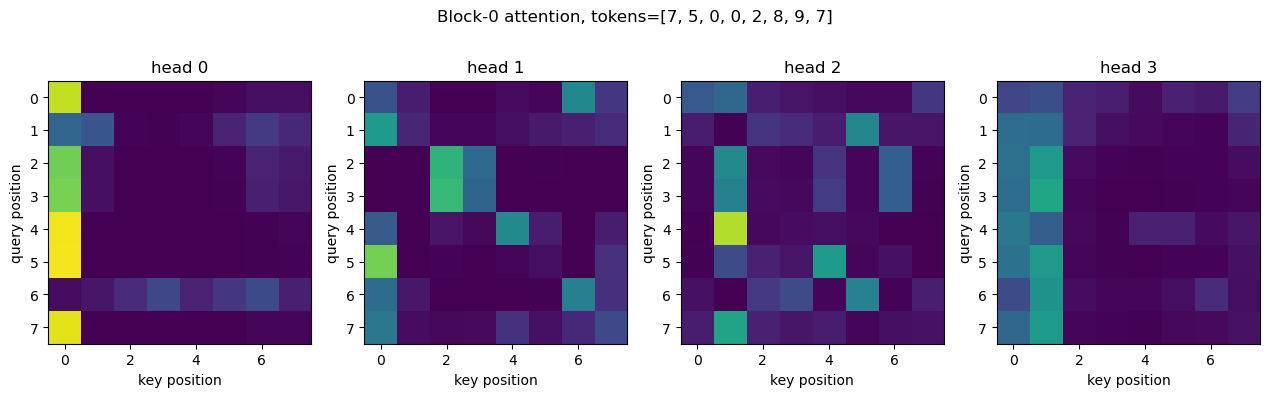

In [17]:
model = with_pe[2]
sample = X_test[np.where(y_test[:, 0] == 1)[0][0]][None, :]
model.forward(sample)
A = model.blocks[0].mha.A[0]

fig, axes = plt.subplots(1, A.shape[0], figsize=(3.2 * A.shape[0], 3.6))
for h, ax in enumerate(axes):
    ax.imshow(A[h], cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"head {h}"); ax.set_xlabel("key position"); ax.set_ylabel("query position")
fig.suptitle(f"Block-0 attention, tokens={sample[0].tolist()}", y=1.04)
plt.tight_layout()
plt.show()

With positional encoding the model solves the task (100%); without it, accuracy collapses toward chance — attention alone is order-blind.

That completes the core roadmap: perceptron → backprop → optimizers → regularization → CNN → RNN/LSTM → transformer.